In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [4]:

import zipfile

with zipfile.ZipFile("hotel_bookings.csv.zip", "r") as zip_ref:
    zip_ref.extractall()

print("Dataset extracted successfully!")


Dataset extracted successfully!


In [5]:

df = pd.read_csv("hotel_bookings.csv")

df.head()


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [6]:

df.shape


(119390, 32)

In [28]:
print("Duplicate rows:", df_clean.duplicated().sum())

Duplicate rows: 31980


In [29]:
duplicate_percentage = (df_clean.duplicated().sum() / len(df_clean)) * 100

print("Duplicate percentage:", round(duplicate_percentage, 2), "%")

Duplicate percentage: 26.83 %


### Duplicate Records Investigation

- Total original records: 119,390
- Identical rows identified: 31,980
- Duplicate percentage: 26.83%

**Decision:** Retain duplicate records.

**Reason:** The dataset does not contain a unique booking identifier. Different customers may have identical booking details, so removing these records could delete legitimate bookings.

**Limitation:** Identical rows are not necessarily erroneous duplicate bookings.

In [30]:
print("Total missing values in cleaned data:", df_clean.isnull().sum().sum())

Total missing values in cleaned data: 0


In [31]:
print("Final cleaned dataset shape:", df_clean.shape)

Final cleaned dataset shape: (119208, 32)


# Exploratory Data Analysis (EDA)

## 1. Hotel Booking Distribution

Business Question: How many bookings were made for each hotel type?

In [32]:
hotel_counts = df_clean["hotel"].value_counts()

print(hotel_counts)

hotel
City Hotel      79162
Resort Hotel    40046
Name: count, dtype: int64


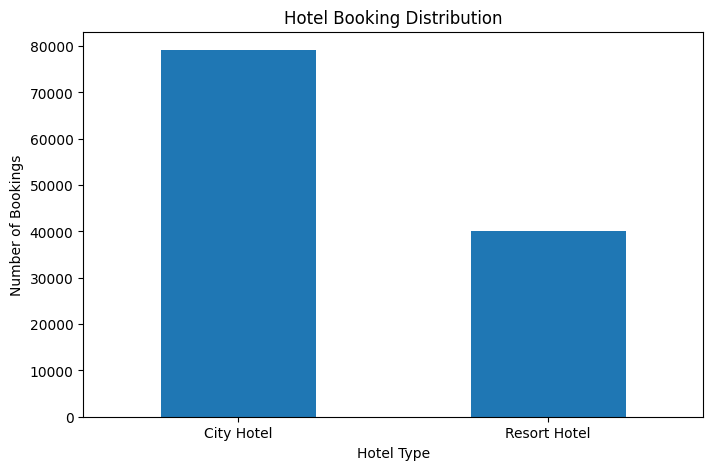

In [33]:
plt.figure(figsize=(8, 5))

hotel_counts.plot(kind="bar")

plt.title("Hotel Booking Distribution")
plt.xlabel("Hotel Type")
plt.ylabel("Number of Bookings")

plt.xticks(rotation=0)
plt.show()

### Key Finding: Hotel Booking Distribution

- City Hotels recorded **79,162 bookings (66.4%)**.
- Resort Hotels recorded **40,046 bookings (33.6%)**.
- City Hotels accounted for approximately twice as many bookings as Resort Hotels.

**Business Insight:** City Hotels represent the larger share of booking activity in this dataset.

**Limitation:** These figures represent booking records, including cancellations, rather than completed stays.

## 2. Hotel Cancellation Rate Analysis

**Business Question:** Which hotel type has the higher cancellation rate?

In [34]:
cancellation_rates = (
    df_clean.groupby("hotel")["is_canceled"].mean() * 100
)

print(cancellation_rates.round(2))

hotel
City Hotel      41.79
Resort Hotel    27.77
Name: is_canceled, dtype: float64


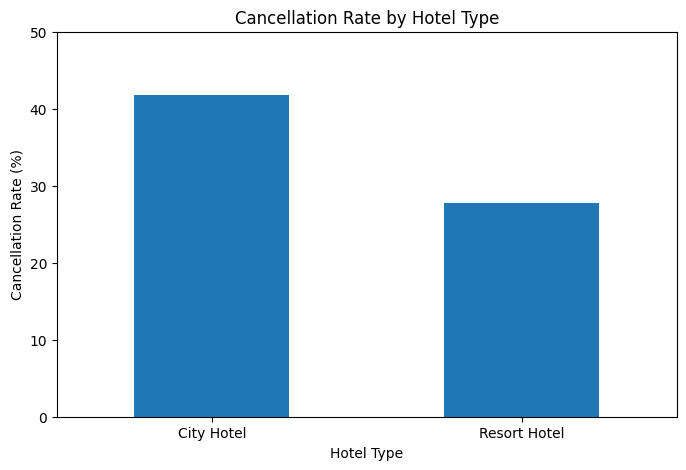

In [35]:
plt.figure(figsize=(8, 5))

cancellation_rates.plot(kind="bar")

plt.title("Cancellation Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")

plt.xticks(rotation=0)
plt.ylim(0, 50)

plt.show()

### Key Finding: Hotel Cancellation Rates

- City Hotels recorded a cancellation rate of **41.79%**.
- Resort Hotels recorded a cancellation rate of **27.77%**.
- City Hotels had a cancellation rate **14.02 percentage points higher** than Resort Hotels.

**Business Insight:** City Hotels experience a substantially higher proportion of canceled bookings compared with Resort Hotels.

**Business Recommendation:** Hotel management should investigate the factors contributing to higher City Hotel cancellations, such as booking lead times, customer segments, and deposit policies.

**Limitation:** This analysis identifies an association between hotel type and cancellation rates but does not establish the causes of cancellations.

## 3. Monthly Hotel Booking Trends

**Business Question:** Which months have the highest and lowest numbers of hotel bookings?

In [36]:
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_bookings = df_clean["arrival_date_month"].value_counts()

monthly_bookings = monthly_bookings.reindex(month_order)

print(monthly_bookings)

arrival_date_month
January       5921
February      8052
March         9766
April        11078
May          11780
June         10929
July         12644
August       13861
September    10500
October      11147
November      6771
December      6759
Name: count, dtype: int64


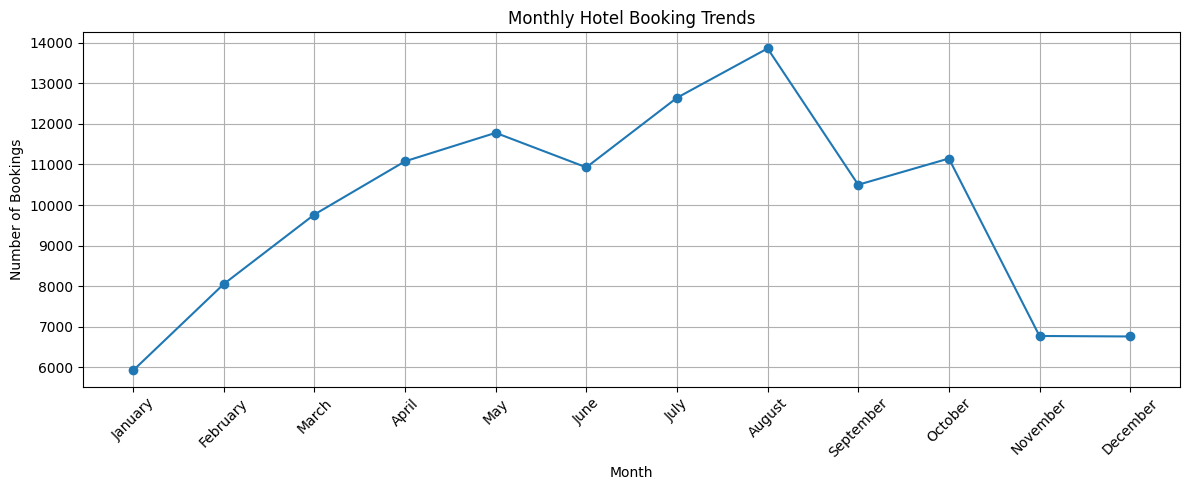

In [37]:
plt.figure(figsize=(12, 5))

monthly_bookings.plot(kind="line", marker="o")

plt.title("Monthly Hotel Booking Trends")
plt.xlabel("Month")
plt.ylabel("Number of Bookings")

plt.xticks(
    range(12),
    month_order,
    rotation=45
)

plt.grid(True)
plt.tight_layout()
plt.show()

### Key Finding: Monthly Hotel Booking Trends

- **August** recorded the highest number of bookings, with **13,861**.
- **July** recorded the second-highest number, with **12,644**.
- **January** recorded the lowest number, with **5,921**.
- Booking activity was generally higher during the summer months.

**Business Insight:** The dataset suggests that hotel booking activity is stronger during the summer, particularly in July and August.

**Business Recommendation:** Hotel management should investigate seasonal demand patterns when planning staffing, marketing campaigns, and operational resources.

**Limitation:** These figures combine booking records across multiple years and include canceled bookings. They do not represent completed stays or a single year's monthly trend.

## 4. Booking Lead Time and Cancellation Analysis

**Business Question:** How do cancellation rates differ between customers who book shortly before arrival and those who book further in advance?

In [38]:
df_clean["lead_time_group"] = pd.cut(
    df_clean["lead_time"],
    bins=[-1, 7, 30, 90, 180, float("inf")],
    labels=[
        "0-7 days",
        "8-30 days",
        "31-90 days",
        "91-180 days",
        "181+ days"
    ]
)

lead_time_analysis = (
    df_clean.groupby("lead_time_group", observed=True)
    .agg(
        total_bookings=("is_canceled", "size"),
        cancellation_rate=("is_canceled", "mean")
    )
)

lead_time_analysis["cancellation_rate"] *= 100

print(lead_time_analysis.round(2))

                 total_bookings  cancellation_rate
lead_time_group                                   
0-7 days                  19635               9.60
8-30 days                 18945              27.89
31-90 days                29528              37.73
91-180 days               26420              44.74
181+ days                 24680              57.01


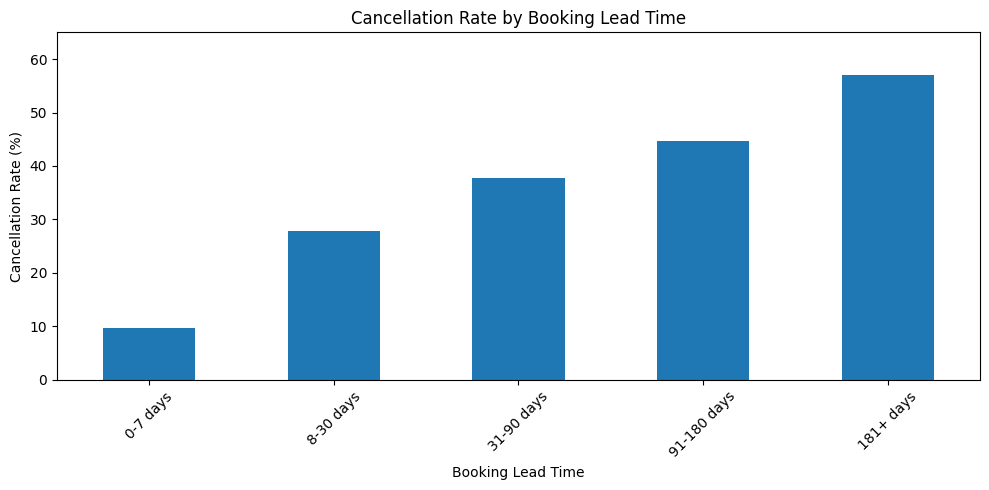

In [39]:
plt.figure(figsize=(10, 5))

lead_time_analysis["cancellation_rate"].plot(
    kind="bar"
)

plt.title("Cancellation Rate by Booking Lead Time")
plt.xlabel("Booking Lead Time")
plt.ylabel("Cancellation Rate (%)")

plt.xticks(rotation=45)
plt.ylim(0, 65)

plt.tight_layout()
plt.show()

### Key Finding: Booking Lead Time and Cancellation Rates

- Customers booking **0–7 days** before arrival had the lowest cancellation rate at **9.60%**.
- Customers booking **181+ days** in advance had the highest cancellation rate at **57.01%**.
- Cancellation rates increased consistently across the five booking lead-time groups.
- The difference between the shortest and longest booking lead-time groups was **47.41 percentage points**.

**Business Insight:** Bookings made further in advance were associated with higher cancellation rates in this dataset.

**Business Recommendation:** Hotel management should investigate whether flexible cancellation policies, booking reminders, or deposit requirements could help reduce cancellations among customers booking far in advance.

**Limitation:** This analysis identifies an association between booking lead time and cancellations. It does not prove that booking earlier causes cancellations.

## 5. Customer Type and Cancellation Analysis

**Business Question:** Which customer type has the highest cancellation rate?

In [40]:
customer_analysis = (
    df_clean.groupby("customer_type")
    .agg(
        total_bookings=("is_canceled", "size"),
        cancellation_rate=("is_canceled", "mean")
    )
)

customer_analysis["cancellation_rate"] *= 100

print(customer_analysis.round(2))

                 total_bookings  cancellation_rate
customer_type                                     
Contract                   4072              30.99
Group                       574              10.10
Transient                 89475              40.79
Transient-Party           25087              25.45


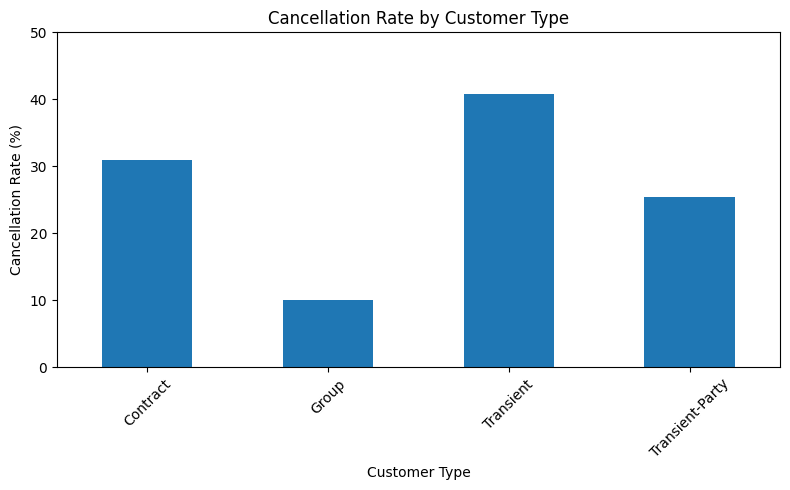

In [41]:
plt.figure(figsize=(8, 5))

customer_analysis["cancellation_rate"].plot(kind="bar")

plt.title("Cancellation Rate by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Cancellation Rate (%)")

plt.xticks(rotation=45)
plt.ylim(0, 50)

plt.tight_layout()
plt.show()

### Key Finding: Customer Type and Cancellation Rates

- **Transient customers** recorded the highest cancellation rate at **40.79%**, across 89,475 bookings.
- **Contract customers** had a cancellation rate of **30.99%**.
- **Transient-Party customers** recorded a cancellation rate of **25.45%**.
- **Group customers** had the lowest cancellation rate at **10.10%**, across 574 bookings.
- The difference between Transient and Group cancellation rates was **30.69 percentage points**.

**Business Insight:** Transient customers represent the largest booking segment and have the highest cancellation rate, making them an important group for hotel management to investigate.

**Business Recommendation:** Hotel management should examine cancellation patterns among Transient customers and evaluate whether booking reminders, deposit policies, or targeted communication could reduce cancellations.

**Limitation:** Customer type is associated with different cancellation rates, but this analysis does not establish why those differences occur. The Group segment also has a relatively small sample size.

## 6. Deposit Type and Cancellation Analysis

**Business Question:** How do cancellation rates differ across hotel booking deposit types?

In [42]:
deposit_analysis = (
    df_clean.groupby("deposit_type")
    .agg(
        total_bookings=("is_canceled", "size"),
        cancellation_rate=("is_canceled", "mean")
    )
)

deposit_analysis["cancellation_rate"] *= 100

print(deposit_analysis.round(2))

              total_bookings  cancellation_rate
deposit_type                                   
No Deposit            104460              28.40
Non Refund             14586              99.36
Refundable               162              22.22


### Project Overview

This project used Python, Pandas, and Matplotlib to clean and explore a hotel booking dataset. After cleaning, the dataset contained **119,208 booking records and 32 columns**.

The objective was to identify booking patterns, investigate cancellation rates, and provide actionable business recommendations.

### Key Findings

1. **Hotel Booking Distribution:** City Hotels accounted for 66.4% of bookings, compared with 33.6% for Resort Hotels.

2. **Hotel Cancellation Rates:** City Hotels had a higher cancellation rate (41.79%) than Resort Hotels (27.77%).

3. **Monthly Booking Trends:** August recorded the highest booking volume (13,861), while January recorded the lowest (5,921).

4. **Booking Lead Time:** Cancellation rates increased from 9.60% for bookings made 0–7 days before arrival to 57.01% for bookings made 181+ days in advance.

5. **Customer Type:** Transient customers had the highest cancellation rate (40.79%), while Group customers had the lowest (10.10%).

6. **Deposit Type:** Non Refund bookings had a cancellation rate of 99.36%, compared with 28.40% for No Deposit bookings.

7. **Market Segment:** Group bookings recorded a cancellation rate of 61.11%, the highest among substantial market segments.

### Business Recommendations

- Investigate the factors contributing to higher cancellation rates at City Hotels.
- Review booking policies and communication strategies for customers booking far in advance.
- Examine cancellation patterns among Transient customers and Group market-segment bookings.
- Investigate the exceptionally high cancellation rate associated with Non Refund bookings.
- Consider seasonal booking patterns when planning staffing, marketing, and operational resources.

### Project Limitations

The analysis is based on historical booking records, including cancellations, rather than completed hotel stays. Monthly results combine records across multiple years. The findings identify associations and should not be interpreted as proof of causation. Categories with very small sample sizes require cautious interpretation.

### Tools and Skills Demonstrated

**Python | Pandas | Matplotlib | Data Cleaning | Exploratory Data Analysis | Data Visualization | Business Insights**

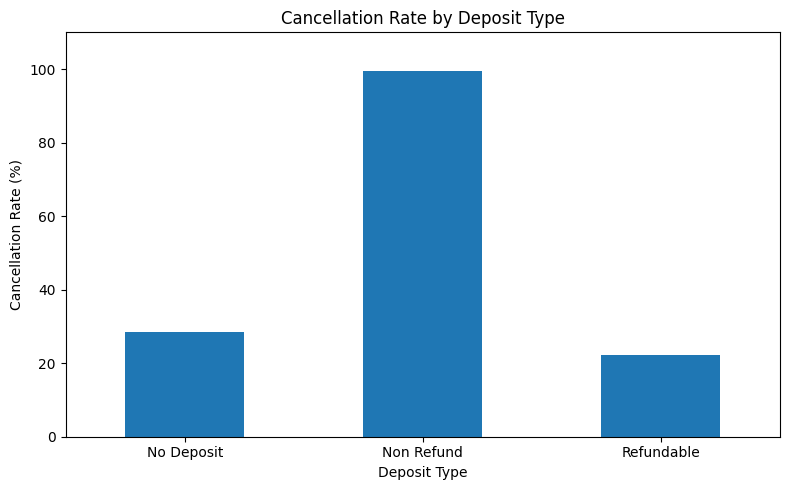

In [43]:
plt.figure(figsize=(8, 5))

deposit_analysis["cancellation_rate"].plot(kind="bar")

plt.title("Cancellation Rate by Deposit Type")
plt.xlabel("Deposit Type")
plt.ylabel("Cancellation Rate (%)")

plt.xticks(rotation=0)
plt.ylim(0, 110)

plt.tight_layout()
plt.show()

### Key Finding: Deposit Type and Cancellation Rates

- **Non Refund** bookings recorded the highest cancellation rate at **99.36%**, across 14,586 bookings.
- **No Deposit** bookings had a cancellation rate of **28.40%**, across 104,460 bookings.
- **Refundable** bookings recorded the lowest cancellation rate at **22.22%**, across only 162 bookings.
- The difference between Non Refund and No Deposit cancellation rates was **70.96 percentage points**.

**Business Insight:** Deposit type is strongly associated with cancellation rates in this dataset. The exceptionally high cancellation rate among Non Refund bookings warrants further investigation.

**Business Recommendation:** Hotel management should investigate the booking conditions, customer characteristics, and cancellation policies associated with Non Refund reservations before making changes to deposit policies.

**Limitation:** This analysis shows an association, not causation. The Refundable category also has a very small sample size, so its cancellation rate should be interpreted cautiously.

## 7. Market Segment and Cancellation Analysis

**Business Question:** Which market segments have the highest hotel booking cancellation rates?

In [44]:
market_segment_analysis = (
    df_clean.groupby("market_segment")
    .agg(
        total_bookings=("is_canceled", "size"),
        cancellation_rate=("is_canceled", "mean")
    )
)

market_segment_analysis["cancellation_rate"] *= 100

market_segment_analysis = market_segment_analysis.sort_values(
    "cancellation_rate", ascending=False
)

print(market_segment_analysis.round(2))

                total_bookings  cancellation_rate
market_segment                                   
Undefined                    2             100.00
Groups                   19790              61.11
Online TA                56408              36.76
Offline TA/TO            24181              34.33
Aviation                   235              22.13
Corporate                 5282              18.76
Direct                   12582              15.37
Complementary              728              12.23


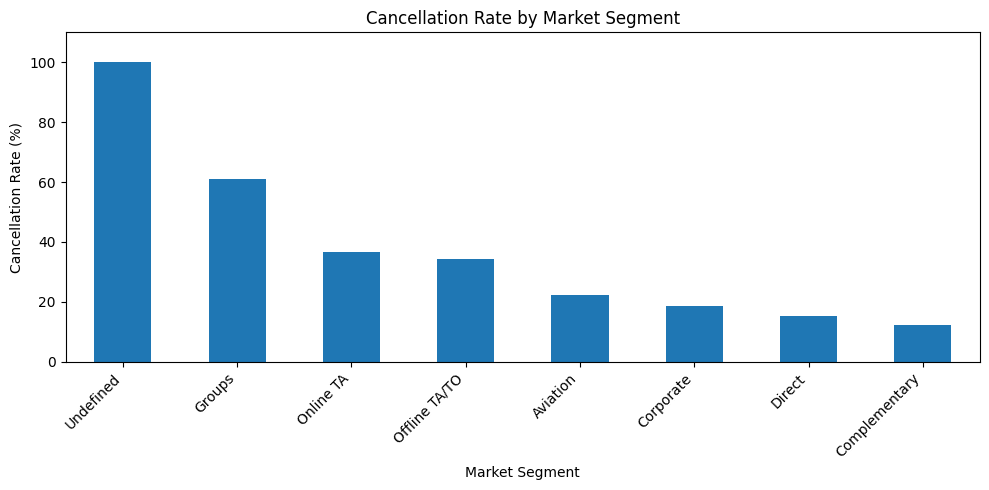

In [45]:
plt.figure(figsize=(10, 5))

market_segment_analysis["cancellation_rate"].plot(kind="bar")

plt.title("Cancellation Rate by Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("Cancellation Rate (%)")

plt.xticks(rotation=45, ha="right")
plt.ylim(0, 110)

plt.tight_layout()
plt.show()

### Key Finding: Market Segment and Cancellation Rates

- **Undefined** recorded a 100% cancellation rate, but this category contained only 2 bookings.
- **Groups** recorded the highest cancellation rate among substantial market segments at **61.11%**, across 19,790 bookings.
- **Online TA** recorded a cancellation rate of **36.76%**, across 56,408 bookings.
- **Offline TA/TO** recorded a cancellation rate of **34.33%**, across 24,181 bookings.
- **Complimentary** recorded the lowest cancellation rate at **12.23%**, across 728 bookings.

**Business Insight:** Group bookings have a particularly high cancellation rate compared with other substantial market segments. Online travel agencies also represent a large volume of bookings with a notable cancellation rate.

**Business Recommendation:** Hotel management should investigate cancellation patterns among Group and Online TA bookings and consider whether targeted booking reminders, deposit policies, or reservation confirmation procedures could help reduce cancellations.

**Limitation:** The Undefined category contains only two bookings, making its 100% cancellation rate unreliable for general conclusions. These results show associations rather than causes.

In [10]:

df_clean["children"] = df_clean["children"].fillna(0)

print("Missing children values:", df_clean["children"].isnull().sum())


Missing children values: 0


In [11]:

df_clean["country"] = df_clean["country"].fillna("Unknown")

print("Missing country values:", df_clean["country"].isnull().sum())


Missing country values: 0


In [12]:

df_clean["agent"] = df_clean["agent"].fillna(0)

print("Missing agent values:", df_clean["agent"].isnull().sum())


Missing agent values: 0


In [13]:

df_clean["company"] = df_clean["company"].fillna(0)

print("Missing company values:", df_clean["company"].isnull().sum())


Missing company values: 0


In [14]:

print("Total missing values:", df_clean.isnull().sum().sum())


Total missing values: 0


In [15]:

duplicate_count = df_clean.duplicated().sum()

print("Total duplicate rows:", duplicate_count)


Total duplicate rows: 31994


In [16]:

df_clean[df_clean.duplicated(keep=False)].head(10)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,0.0,0,Transient,98.00,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,0.0,0,Transient,98.00,0,1,Check-Out,2015-07-03
21,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,0.0,0,Transient,84.67,0,1,Check-Out,2015-07-07
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,0.0,0,Transient,84.67,0,1,Check-Out,2015-07-07
39,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,No Deposit,250.0,0.0,0,Transient,137.00,0,1,Check-Out,2015-07-07
43,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,No Deposit,250.0,0.0,0,Transient,137.00,0,1,Check-Out,2015-07-07
132,Resort Hotel,1,5,2015,July,28,5,1,0,2,...,No Deposit,240.0,0.0,0,Transient,97.00,0,0,Canceled,2015-07-01
138,Resort Hotel,1,5,2015,July,28,5,1,0,2,...,No Deposit,240.0,0.0,0,Transient,97.00,0,0,Canceled,2015-07-01
198,Resort Hotel,0,0,2015,July,28,7,0,1,1,...,No Deposit,240.0,0.0,0,Transient,109.80,0,3,Check-Out,2015-07-08
200,Resort Hotel,0,0,2015,July,28,7,0,1,1,...,No Deposit,240.0,0.0,0,Transient,109.80,0,3,Check-Out,2015-07-08


In [17]:

df_clean.dtypes


,0
hotel,object
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,object
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


In [18]:

df_clean["children"] = df_clean["children"].astype(int)

print("Children column data type:", df_clean["children"].dtype)


Children column data type: int64


In [19]:

df_clean["reservation_status_date"] = pd.to_datetime(
    df_clean["reservation_status_date"]
)

print("Date column type:", df_clean["reservation_status_date"].dtype)


Date column type: datetime64[ns]


In [20]:

zero_guest_bookings = df_clean[
    (df_clean["adults"] == 0) &
    (df_clean["children"] == 0) &
    (df_clean["babies"] == 0)
]

print("Bookings with zero guests:", len(zero_guest_bookings))


Bookings with zero guests: 180


In [21]:

df_clean = df_clean[
    (df_clean["adults"] +
     df_clean["children"] +
     df_clean["babies"]) > 0
].copy()

print("Remaining rows:", len(df_clean))


Remaining rows: 119210


In [22]:

columns = ["adults", "children", "babies"]

negative_values = (df_clean[columns] < 0).sum()

print("Negative values:")
print(negative_values)


Negative values:
adults      0
children    0
babies      0
dtype: int64


In [23]:

print("Minimum ADR:", df_clean["adr"].min())
print("Maximum ADR:", df_clean["adr"].max())

print("Negative ADR values:", (df_clean["adr"] < 0).sum())


Minimum ADR: -6.38
Maximum ADR: 5400.0
Negative ADR values: 1


In [24]:

negative_adr = df_clean[df_clean["adr"] < 0]

negative_adr[
    ["hotel", "adr", "is_canceled",
     "adults", "children", "babies",
     "reservation_status"]
]


,hotel,adr,is_canceled,adults,children,babies,reservation_status
14969,Resort Hotel,-6.38,0,2,0,0,Check-Out


In [25]:

df_clean = df_clean[df_clean["adr"] >= 0].copy()

print("Remaining rows:", len(df_clean))
print("Negative ADR values:", (df_clean["adr"] < 0).sum())


Remaining rows: 119209
Negative ADR values: 0


In [26]:

highest_adr = df_clean.nlargest(10, "adr")

highest_adr[
    ["hotel", "adr", "is_canceled",
     "adults", "children", "babies",
     "reservation_status"]
]


,hotel,adr,is_canceled,adults,children,babies,reservation_status
48515,City Hotel,5400.00,1,2,0,0,Canceled
111403,City Hotel,510.00,0,1,0,0,Check-Out
15083,Resort Hotel,508.00,0,2,0,0,Check-Out
103912,City Hotel,451.50,0,2,2,0,Check-Out
13142,Resort Hotel,450.00,1,2,0,0,Canceled
13391,Resort Hotel,437.00,1,2,2,0,Canceled
39155,Resort Hotel,426.25,0,2,2,0,Check-Out
39568,Resort Hotel,402.00,0,3,1,0,Check-Out
39118,Resort Hotel,397.38,0,3,2,0,Check-Out
13323,Resort Hotel,392.00,1,2,1,0,Canceled


In [27]:

df_clean = df_clean[df_clean["adr"] < 5400].copy()

print("Remaining rows:", len(df_clean))
print("Maximum ADR:", df_clean["adr"].max())


Remaining rows: 119208
Maximum ADR: 510.0


## Final Project Summary and Business Recommendations

### Project Summary

This project used Python and Pandas to clean and explore a hotel booking dataset.

**Data Cleaning Results:**
- Identified and handled missing values in the children, country, agent, and company columns.
- Identified 31,994 duplicate rows for further review.
- Removed 180 bookings with zero guests.
- Removed one booking with a negative Average Daily Rate (ADR).
- Excluded one unusually high ADR value of 5,400 for the cleaned analysis dataset.
- Final cleaned dataset: **119,208 bookings**.

**Business Recommendations:**
- Investigate high cancellation rates among Group and Online TA bookings.
- Consider booking reminders and reservation confirmation procedures to help reduce cancellations.
- Monitor unusual ADR values to improve data quality and reporting accuracy.

**Limitation:** The analysis identifies patterns and associations, not proven causes. Duplicate records and unusually high ADR values should be reviewed before deciding whether to remove them.